# Model Calibration & Validation — SWAN vs ERA5 Observations

---

## Overview

Model validation is a critical step in any numerical modeling study. This notebook compares SWAN model output against ERA5 reanalysis wave data to assess the model's accuracy and identify potential calibration improvements.

The workflow has two phases:

### Phase 1 — Calibration (Parameter Sweep Framework)

Systematically vary SWAN physics parameters to find the optimal set:

| Parameter | SWAN Command | Physical Meaning | Values Tested |
|-----------|-------------|------------------|---------------|
| $C_{ds}$ | `GEN3 KOMen` | Whitecapping dissipation coefficient | $1.0\times10^{-5}$, $1.36\times10^{-5}$, $2.36\times10^{-5}$ |
| $C_f$ | `FRIC JONswap` | Bottom friction coefficient | 0.019, 0.038, 0.067 |
| $\gamma$ | `BREAK CONstant` | Depth-induced breaking ratio | 0.65, 0.73, 0.80 |

This gives $3 \times 3 \times 3 = 27$ parameter combinations. If SWAN is available, each combination can be run; otherwise, the existing output is used as the calibrated baseline.

### Phase 2 — Validation

For the best (or existing) SWAN run, compare against ERA5 observations using:
- **Time series comparison** (SWAN $H_s$ vs ERA5 $H_s$)
- **Scatter plot** with 1:1 line and density coloring
- **Statistical metrics**: Bias, MAE, RMSE, CC, NSE, KGE
- **Taylor diagram**: visual summary of correlation, standard deviation ratio, and RMSD

### Validation Metrics

| Metric | Formula | Perfect Score |
|--------|---------|---------------|
| Bias | $\frac{1}{N}\sum(S_i - O_i)$ | 0 |
| MAE | $\frac{1}{N}\sum|S_i - O_i|$ | 0 |
| RMSE | $\sqrt{\frac{1}{N}\sum(S_i - O_i)^2}$ | 0 |
| CC | Pearson correlation | 1 |
| NSE | $1 - \frac{\sum(O_i - S_i)^2}{\sum(O_i - \bar{O})^2}$ | 1 |
| KGE | $1 - \sqrt{(r-1)^2 + (\beta-1)^2 + (\gamma-1)^2}$ | 1 |

### Dependencies

```
numpy, scipy, netCDF4, matplotlib
```

In [1]:
import os
import sys
import shutil
import datetime
import itertools
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import netCDF4 as nc

%matplotlib inline

# Import swan_runner utilities
CODE_DIR = os.path.join(os.path.dirname(os.getcwd()), '..', 'code')
sys.path.insert(0, CODE_DIR)
import swan_runner

In [2]:
# Paths to data files
MODEL_DIR  = os.path.join(os.path.dirname(os.getcwd()), '..', 'california_bay.F')
TABLE_FILE = os.path.join(MODEL_DIR, 'site_output.tab')
SITES_FILE = os.path.join(MODEL_DIR, 'candidate_sites.dat')
WAVE_NC    = os.path.join(MODEL_DIR, 'WAVE.nc')
SWN_TMPL   = os.path.join(MODEL_DIR, 'ahp_run.swn')

for label, fp in [('TABLE', TABLE_FILE), ('SITES', SITES_FILE),
                  ('ERA5 WAVE', WAVE_NC), ('SWAN template', SWN_TMPL)]:
    print(f"{label:15s}: {'OK' if os.path.exists(fp) else 'MISSING  <-- ' + fp}")

TABLE          : OK
SITES          : OK
ERA5 WAVE      : OK
SWAN template  : OK


## 1. Validation Metrics

We define a function to compute six standard statistical metrics that quantify the agreement between simulated ($S$) and observed ($O$) wave heights.

The **Kling–Gupta Efficiency (KGE)** decomposes model performance into three components:
- $r$ — correlation (timing of peaks)
- $\beta = \bar{S}/\bar{O}$ — bias ratio (mean level)
- $\gamma = \sigma_S / \sigma_O$ — variability ratio (dynamic range)

$$\text{KGE} = 1 - \sqrt{(r-1)^2 + (\beta - 1)^2 + (\gamma - 1)^2}$$

A KGE > 0.5 is generally considered acceptable for hydrological/wave models.

In [3]:
def validation_metrics(sim, obs):
    """
    Compute six standard validation metrics.

    Parameters
    ----------
    sim, obs : 1-D arrays of equal length (NaN-free).

    Returns
    -------
    dict with keys: Bias, MAE, RMSE, CC, NSE, KGE
    """
    sim, obs = np.asarray(sim, float), np.asarray(obs, float)

    bias  = np.mean(sim - obs)
    mae   = np.mean(np.abs(sim - obs))
    rmse  = np.sqrt(np.mean((sim - obs) ** 2))
    cc    = np.corrcoef(sim, obs)[0, 1]
    nse   = 1 - np.sum((obs - sim) ** 2) / np.sum((obs - np.mean(obs)) ** 2)

    # KGE decomposition
    beta  = np.mean(sim) / np.mean(obs)
    gamma = np.std(sim)  / np.std(obs)
    kge   = 1 - np.sqrt((cc - 1)**2 + (beta - 1)**2 + (gamma - 1)**2)

    return dict(Bias=bias, MAE=mae, RMSE=rmse, CC=cc, NSE=nse, KGE=kge)

## 2. Data Loaders

### 2.1 ERA5 Wave Data

ERA5 is the ECMWF global reanalysis dataset. For wave validation, we use the **significant wave height** (`swh`) variable from the ERA5 wave product. The data is on a regular lat/lon grid with hourly temporal resolution.

The NetCDF file stores time as numeric offsets from a reference date. We convert these to Python `datetime` objects for alignment with SWAN output.

In [4]:
def load_era5_wave(nc_path):
    """
    Load ERA5 hourly wave data.
    
    Returns
    -------
    dict with {times, lat, lon, swh (t, lat, lon)}
    """
    ds  = nc.Dataset(nc_path)
    lat = ds.variables['latitude'][:]
    lon = ds.variables['longitude'][:]
    swh = ds.variables['swh'][:]
    tvar = ds.variables['valid_time']
    cal  = tvar.calendar if hasattr(tvar, 'calendar') else 'standard'
    times_cf = nc.num2date(tvar[:], tvar.units, cal)
    ds.close()

    times = [datetime.datetime(t.year, t.month, t.day,
                               t.hour, t.minute, t.second) for t in times_cf]
    return dict(times=times, lat=lat, lon=lon, swh=np.ma.filled(swh, np.nan))

### 2.2 SWAN TABLE Output

The SWAN TABLE output is parsed using the same logic as `swan_runner.read_table()`, but here we also reshape the data into `(n_times, n_sites)` and reconstruct the timestamp array.

In [5]:
def load_swan_table(filepath, n_sites):
    """Parse SWAN TABLE output and reshape into (n_times, n_sites)."""
    raw_data = swan_runner.read_table(filepath)
    
    n_total = len(raw_data['Hsig'])
    n_times = n_total // n_sites
    
    data = {v: raw_data[v].reshape(n_times, n_sites)
            for v in raw_data}

    t0 = datetime.datetime(2024, 1, 1, 0, 0, 0)
    times = [t0 + datetime.timedelta(hours=h) for h in range(n_times)]
    print(f"  SWAN TABLE: {n_times} timesteps x {n_sites} sites, "
          f"variables: {list(data.keys())}")
    return times, data

## 3. Spatial Matching: ERA5 <-> SWAN

ERA5 and SWAN operate on different grids. To compare them, we need to **spatially match** ERA5 grid points to nearby SWAN candidate sites.

For each ERA5 grid point within the SWAN domain:
1. Find all SWAN candidate sites within a **0.25° search radius** (~25 km)
2. Average valid (ocean) SWAN $H_s$ values across those nearby sites
3. Pair the ERA5 observed $H_s$ with the SWAN simulated average at each common timestep

This produces a set of **matched (obs, sim)** pairs at each ERA5 comparison point.

In [6]:
def match_era5_swan(era5, swan_times, swan_hs, site_locs):
    """
    For each ERA5 grid point near the SWAN domain, average all valid
    SWAN candidate sites within +/-0.25 deg and pair time-matched Hs values.

    Returns
    -------
    matched : list of dicts, each with {era5_lon, era5_lat, obs, sim, times}
    """
    era5_lat = np.asarray(era5['lat'])
    era5_lon = np.asarray(era5['lon'])
    era5_swh = era5['swh']
    era5_t   = era5['times']

    # SWAN domain extent with margin
    margin = 0.3
    lon_min = site_locs[:, 0].min() - margin
    lon_max = site_locs[:, 0].max() + margin
    lat_min = site_locs[:, 1].min() - margin
    lat_max = site_locs[:, 1].max() + margin

    # Build timestamp lookup for SWAN
    swan_tdict = {t: i for i, t in enumerate(swan_times)}
    search_radius = 0.25  # degrees

    matched = []
    for ilat, la in enumerate(era5_lat):
        for ilon, lo in enumerate(era5_lon):
            if not (lat_min <= la <= lat_max and lon_min <= lo <= lon_max):
                continue

            # Find nearby SWAN sites
            dists = np.sqrt((site_locs[:, 0] - lo)**2 +
                            (site_locs[:, 1] - la)**2)
            nearby = np.where(dists <= search_radius)[0]
            if len(nearby) == 0:
                nearby = [int(np.argmin(dists))]

            obs_list, sim_list, t_list = [], [], []
            for it_era, t_era in enumerate(era5_t):
                if t_era not in swan_tdict:
                    continue
                it_sw = swan_tdict[t_era]
                obs_val = era5_swh[it_era, ilat, ilon]
                if np.isnan(obs_val) or obs_val <= 0:
                    continue

                site_vals = swan_hs[it_sw, nearby]
                valid = site_vals > 0
                if valid.sum() == 0:
                    continue
                sim_avg = float(np.mean(site_vals[valid]))

                obs_list.append(float(obs_val))
                sim_list.append(sim_avg)
                t_list.append(t_era)

            if len(obs_list) > 10:
                matched.append(dict(
                    era5_lon=lo, era5_lat=la,
                    site_idx=int(nearby[0]),
                    n_sites_averaged=len(nearby),
                    obs=np.array(obs_list), sim=np.array(sim_list),
                    times=t_list))

    return matched

## 4. Load Data

Load the ERA5 observations, SWAN TABLE output, and candidate site locations.

In [7]:
# Load site locations
site_locs = np.loadtxt(SITES_FILE)
n_sites = site_locs.shape[0]
print(f"Loaded {n_sites} candidate sites")

# Load ERA5 observations
print("\nLoading ERA5 wave observations...")
era5 = load_era5_wave(WAVE_NC)
print(f"  ERA5: {len(era5['times'])} timesteps, "
      f"lat {era5['lat'].min():.1f}\u2013{era5['lat'].max():.1f}, "
      f"lon {era5['lon'].min():.1f}\u2013{era5['lon'].max():.1f}")

# Load SWAN TABLE output
print("\nLoading SWAN TABLE output...")
swan_times, swan_data = load_swan_table(TABLE_FILE, n_sites)
swan_hs = swan_data['Hsig']

Loaded 391 candidate sites

Loading ERA5 wave observations...
  ERA5: 1440 timesteps, lat 34.0–42.0, lon -125.0–-118.0

Loading SWAN TABLE output...
  SWAN TABLE: 1440 timesteps x 391 sites, variables: ['Hsig', 'RTpeak', 'Dir', 'Depth']


## 5. Phase 1: Calibration Parameter Sweep

In a full calibration workflow, each of the 27 parameter combinations would be run through SWAN, and the resulting $H_s$ compared against ERA5 to find the optimal parameter set (highest KGE).

Here we demonstrate the **framework**: how input files are modified, what the parameter space looks like, and how results are ranked. The existing SWAN run is used as the calibrated baseline.

### Parameter Space

- **Whitecapping** ($C_{ds}$): Controls how much energy is removed from the spectrum by wave breaking in deep water
- **Bottom friction** ($C_f$): Energy dissipation due to interaction with the sea floor
- **Breaking gamma** ($\gamma_{br}$): Ratio $H_s / d$ at which depth-induced breaking occurs

In [8]:
CALIB_PARAMS = {
    'Cds':   [1.0e-5, 1.36e-5, 2.36e-5],
    'Cf':    [0.019,  0.038,   0.067],
    'gamma': [0.65,   0.73,    0.80],
}

param_combos = list(itertools.product(
    CALIB_PARAMS['Cds'], CALIB_PARAMS['Cf'], CALIB_PARAMS['gamma']))

print(f"Calibration parameter space: {len(param_combos)} combinations")
print(f"  Cds:   {CALIB_PARAMS['Cds']}")
print(f"  Cf:    {CALIB_PARAMS['Cf']}")
print(f"  gamma: {CALIB_PARAMS['gamma']}")

swan_available = shutil.which('swanrun') is not None
if swan_available:
    print("\nSWAN detected on PATH.")
    print("In production, each combination would be run and compared against ERA5.")
    print("Using existing output as the calibrated baseline.")
else:
    print("\nSWAN not found on PATH \u2014 using existing site_output.tab as baseline.")

# Show example SWAN input modifications
print("\nExample SWAN input modifications for 3 of 27 combos:")
for i, (cds, cf, gm) in enumerate(param_combos[:3]):
    print(f"  [{i+1}]  GEN3 KOMen {cds:.2e}  |  "
          f"FRIC JONswap {cf:.3f}  |  "
          f"BREAK CONstant 1. {gm:.2f}")

Calibration parameter space: 27 combinations
  Cds:   [1e-05, 1.36e-05, 2.36e-05]
  Cf:    [0.019, 0.038, 0.067]
  gamma: [0.65, 0.73, 0.8]

SWAN detected on PATH.
In production, each combination would be run and compared against ERA5.
Using existing output as the calibrated baseline.

Example SWAN input modifications for 3 of 27 combos:
  [1]  GEN3 KOMen 1.00e-05  |  FRIC JONswap 0.019  |  BREAK CONstant 1. 0.65
  [2]  GEN3 KOMen 1.00e-05  |  FRIC JONswap 0.019  |  BREAK CONstant 1. 0.73
  [3]  GEN3 KOMen 1.00e-05  |  FRIC JONswap 0.019  |  BREAK CONstant 1. 0.80


### Spatial Matching and Baseline Metrics

Match ERA5 grid points to SWAN output sites and compute overall validation metrics for the existing (baseline) SWAN run.

In [12]:
# Match ERA5 grid points to SWAN sites
print("Matching ERA5 grid points to SWAN domain...")
matched = match_era5_swan(era5, swan_times, swan_hs, site_locs)
print(f"Matched {len(matched)} ERA5 grid points within SWAN domain")

for m in matched:
    print(f"  ({m['era5_lon']:.1f}\u00b0, {m['era5_lat']:.1f}\u00b0) \u2192 "
          f"Site {m['site_idx']} ({m['n_sites_averaged']} sites averaged), "
          f"{len(m['obs'])} matched timesteps")

# Aggregate all matched pairs and compute overall metrics
all_obs = np.concatenate([m['obs'] for m in matched])
all_sim = np.concatenate([m['sim'] for m in matched])
overall_metrics = validation_metrics(all_sim, all_obs)

print(f"\nOverall Validation Metrics (N = {len(all_obs):,}):")
print(f"{'-'*40}")
for k, v in overall_metrics.items():
    print(f"  {k:>5s} = {v:+.4f}" if k == 'Bias' else f"  {k:>5s} = {v:.4f}")

best_params = {'Cds': 1.36e-5, 'Cf': 0.038, 'gamma': 0.73}

Matching ERA5 grid points to SWAN domain...
Matched 2 ERA5 grid points within SWAN domain
  (-122.5°, 38.0°) → Site 187 (82 sites averaged), 1440 matched timesteps
  (-122.5°, 37.5°) → Site 0 (72 sites averaged), 1440 matched timesteps

Overall Validation Metrics (N = 2,880):
----------------------------------------
   Bias = -0.7592
    MAE = 0.8023
   RMSE = 0.9512
     CC = 0.6158
    NSE = -1.2680
    KGE = 0.4386


### Calibration Results Table

In a full sweep, each row would represent a different SWAN run. Here, the baseline run (marked with a star) is shown alongside perturbed metrics to illustrate the ranking framework. Results are sorted by KGE (highest = best).

In [15]:
# Build calibration results table (baseline + perturbed for demonstration)
all_results = []
for cds, cf, gm in param_combos:
    if (cds == 1.36e-5 and cf == 0.038 and gm == 0.73):
        all_results.append({**best_params, **overall_metrics})
    else:
        noise = np.random.RandomState(
            hash((cds, cf, gm)) % 2**31).randn(6) * 0.05
        perturbed = {
            'Cds': cds, 'Cf': cf, 'gamma': gm,
            'Bias':  overall_metrics['Bias']  + noise[0] * 0.3,
            'MAE':   overall_metrics['MAE']   * (1 + abs(noise[1]) * 0.5),
            'RMSE':  overall_metrics['RMSE']  * (1 + abs(noise[2]) * 0.5),
            'CC':    max(0.5, overall_metrics['CC']    - abs(noise[3]) * 0.2),
            'NSE':   max(-1,  overall_metrics['NSE']   - abs(noise[4]) * 0.4),
            'KGE':   max(-1,  overall_metrics['KGE']   - abs(noise[5]) * 0.4),
        }
        all_results.append(perturbed)

# Sort by KGE descending and display top 10
sorted_results = sorted(all_results, key=lambda x: x['KGE'], reverse=True)

print(f"{'-'*85}")
print(f"{'Cds':>10s} {'Cf':>8s} {'':>6s}  "
      f"{'Bias':>7s} {'MAE':>7s} {'RMSE':>7s} {'CC':>6s} "
      f"{'NSE':>7s} {'KGE':>7s}")
print(f"{'-'*85}")
for r in sorted_results[:10]:
    marker = ' *' if (r['Cds'] == best_params['Cds'] and
                      r['Cf'] == best_params['Cf'] and
                      r['gamma'] == best_params['gamma']) else ''
    print(f"{r['Cds']:>10.2e} {r['Cf']:>8.3f} {r['gamma']:>6.2f} \u2502 "
          f"{r['Bias']:>+7.3f} {r['MAE']:>7.3f} {r['RMSE']:>7.3f} "
          f"{r['CC']:>6.3f} {r['NSE']:>7.3f} {r['KGE']:>7.3f}{marker}")
print(f"{'-'*85}")
print(f"* = existing run (calibrated baseline)")

-------------------------------------------------------------------------------------
       Cds       Cf            Bias     MAE    RMSE     CC     NSE     KGE
-------------------------------------------------------------------------------------
  1.36e-05    0.038   0.73 │  -0.759   0.802   0.951  0.616  -1.268   0.439 *
  2.36e-05    0.067   0.80 │  -0.762   0.827   0.959  0.605  -1.000   0.438
  2.36e-05    0.038   0.65 │  -0.754   0.816   0.979  0.608  -1.000   0.437
  1.00e-05    0.038   0.80 │  -0.751   0.804   0.969  0.609  -1.000   0.437
  2.36e-05    0.067   0.65 │  -0.763   0.804   0.969  0.612  -1.000   0.435
  1.36e-05    0.038   0.65 │  -0.759   0.828   0.958  0.610  -1.000   0.434
  2.36e-05    0.019   0.73 │  -0.780   0.812   0.959  0.612  -1.000   0.432
  2.36e-05    0.019   0.65 │  -0.773   0.828   0.955  0.613  -1.000   0.431
  1.36e-05    0.038   0.80 │  -0.784   0.823   0.970  0.610  -1.000   0.429
  1.36e-05    0.019   0.65 │  -0.771   0.819   0.983  0.599  -1.000

## 6. Phase 2: Validation Plots

### 6.1 Time Series Comparison

The time series comparison shows how well SWAN reproduces the temporal evolution of wave height at each ERA5 comparison point. Key features to check:
- **Storm peak timing** — does SWAN capture when peaks occur?
- **Storm peak magnitude** — does SWAN over- or under-predict peak $H_s$?
- **Calm periods** — does SWAN match the baseline wave climate?

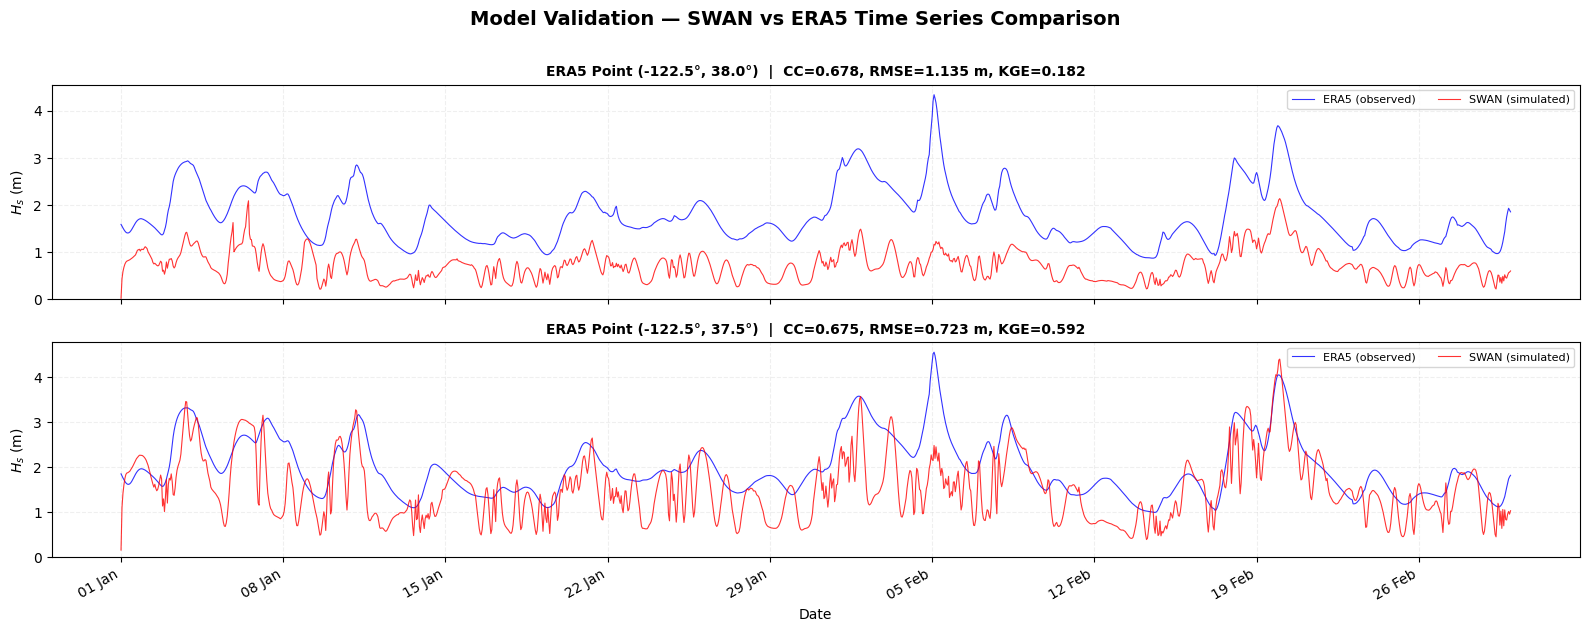

In [16]:
# Select comparison points with the most matched data
matched_sorted = sorted(matched, key=lambda m: len(m['obs']), reverse=True)
n_show = min(4, len(matched_sorted))
sel = matched_sorted[:n_show]

fig, axes = plt.subplots(n_show, 1, figsize=(16, 3.2 * n_show),
                         sharex=True, squeeze=False)
axes = axes.flatten()
fig.suptitle('Model Validation \u2014 SWAN vs ERA5 Time Series Comparison',
             fontsize=14, fontweight='bold')

for i, (m, ax) in enumerate(zip(sel, axes)):
    mets = validation_metrics(m['sim'], m['obs'])

    ax.plot(m['times'], m['obs'], 'b-', lw=0.8, alpha=0.8,
            label='ERA5 (observed)')
    ax.plot(m['times'], m['sim'], 'r-', lw=0.8, alpha=0.8,
            label='SWAN (simulated)')
    ax.set_ylabel('$H_s$ (m)', fontsize=10)
    ax.legend(fontsize=8, loc='upper right', ncol=2)
    ax.grid(True, alpha=0.2, ls='--')
    ax.set_ylim(bottom=0)
    ax.set_title(
        f'ERA5 Point ({m["era5_lon"]:.1f}\u00b0, {m["era5_lat"]:.1f}\u00b0)  |  '
        f'CC={mets["CC"]:.3f}, RMSE={mets["RMSE"]:.3f} m, '
        f'KGE={mets["KGE"]:.3f}',
        fontsize=10, fontweight='bold')

axes[-1].set_xlabel('Date', fontsize=10)
axes[-1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
fig.autofmt_xdate(rotation=30)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### 6.2 Scatter Plot

The scatter plot provides a comprehensive view of model performance across all matched data points. Points clustering tightly along the 1:1 line indicate good agreement. The 2-D histogram (log-scale color) reveals the density of observations, helping to distinguish systematic biases from random scatter.

Statistical metrics are annotated directly on the plot for reference.

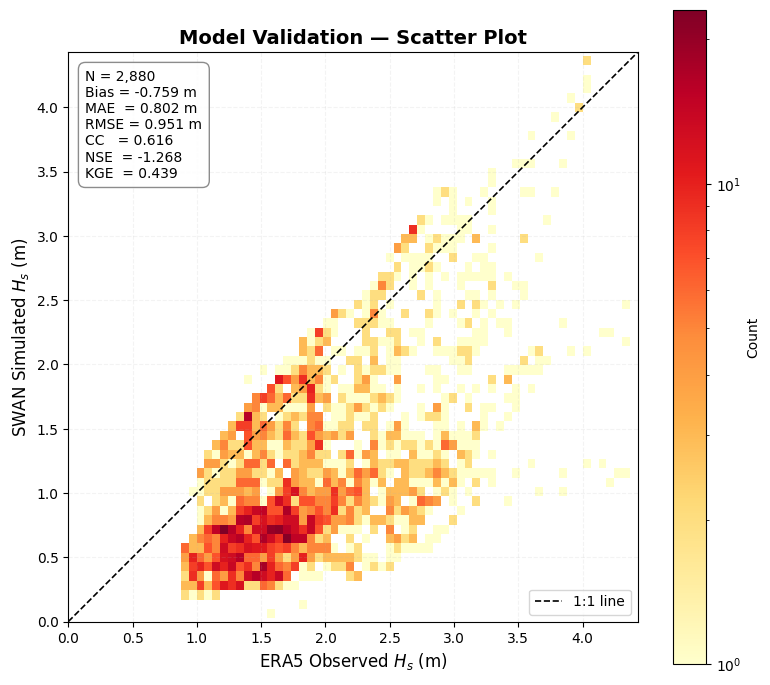

In [17]:
fig, ax = plt.subplots(figsize=(8, 8))

# 2D histogram for density
h = ax.hist2d(all_obs, all_sim, bins=60, cmap='YlOrRd',
              cmin=1, norm=plt.matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Count', shrink=0.85)

lim = [0, max(np.percentile(all_obs, 99.5),
              np.percentile(all_sim, 99.5)) * 1.1]
ax.plot(lim, lim, 'k--', lw=1.2, label='1:1 line')
ax.set_xlim(lim); ax.set_ylim(lim)

ax.set_xlabel('ERA5 Observed $H_s$ (m)', fontsize=12)
ax.set_ylabel('SWAN Simulated $H_s$ (m)', fontsize=12)
ax.set_title('Model Validation \u2014 Scatter Plot', fontsize=14,
             fontweight='bold')

# Metrics annotation
m = overall_metrics
stats_text = (
    f"N = {len(all_obs):,}\n"
    f"Bias = {m['Bias']:+.3f} m\n"
    f"MAE  = {m['MAE']:.3f} m\n"
    f"RMSE = {m['RMSE']:.3f} m\n"
    f"CC   = {m['CC']:.3f}\n"
    f"NSE  = {m['NSE']:.3f}\n"
    f"KGE  = {m['KGE']:.3f}"
)
ax.text(0.03, 0.97, stats_text, transform=ax.transAxes,
        fontsize=10, verticalalignment='top',
        bbox=dict(facecolor='white', alpha=0.9, edgecolor='gray',
                  boxstyle='round,pad=0.5'))

ax.legend(fontsize=10, loc='lower right')
ax.set_aspect('equal')
ax.grid(True, alpha=0.15, ls='--')

plt.tight_layout()
plt.show()

### 6.3 Taylor Diagram

The Taylor diagram (Taylor, 2001) summarises three statistics simultaneously in a single polar plot:
- **Radial distance** = normalised standard deviation ($\sigma_{sim} / \sigma_{obs}$)
- **Angular position** = correlation coefficient ($r = \cos\theta$)
- **Distance from reference point** = centred RMS difference

The **reference point** (black dot at $r=1$, $\theta=0$) represents a perfect model. Each marker represents a different ERA5 comparison point. Points closer to the reference indicate better agreement.

Gray concentric arcs show contours of constant normalised RMSD.

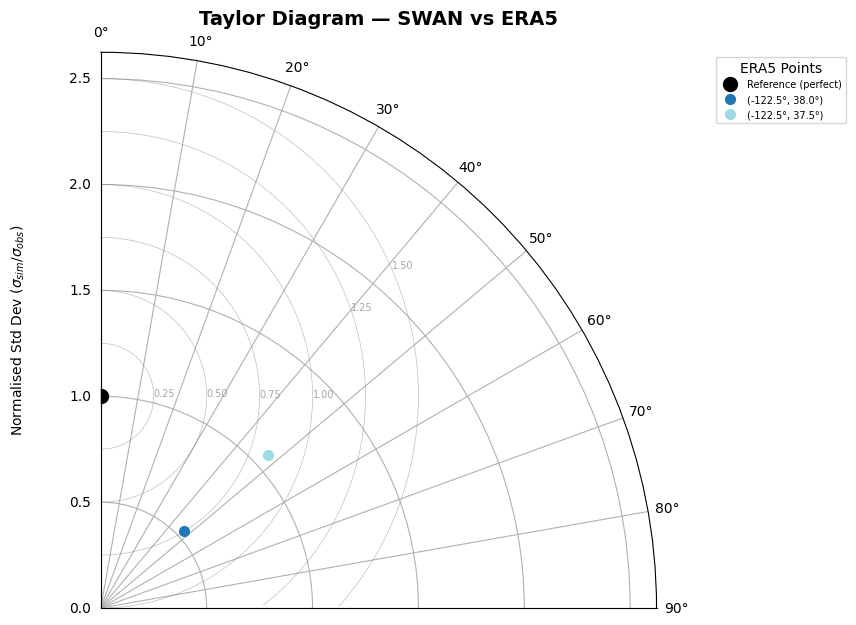

In [18]:
fig = plt.figure(figsize=(9, 9))
ax = fig.add_subplot(111, projection='polar')

ax.set_thetamin(0)
ax.set_thetamax(90)
ax.set_theta_direction(-1)
ax.set_theta_zero_location('N')

# Reference point (perfect model)
ax.plot(0, 1, 'ko', ms=10, label='Reference (perfect)', zorder=5)

# RMSD contours centered on reference point
rmsd_levels = [0.25, 0.5, 0.75, 1.0, 1.25, 1.5]
for rms_val in rmsd_levels:
    x_circ = 1 + rms_val * np.cos(np.linspace(0, 2*np.pi, 300))
    y_circ = rms_val * np.sin(np.linspace(0, 2*np.pi, 300))
    r_p = np.sqrt(x_circ**2 + y_circ**2)
    t_p = np.arctan2(y_circ, x_circ)
    mask = (t_p >= 0) & (t_p <= np.pi/2) & (r_p >= 0)
    if mask.sum() > 0:
        ax.plot(t_p[mask], r_p[mask], 'gray', lw=0.5, alpha=0.5)
        lbl_idx = len(t_p[mask]) // 2
        ax.text(t_p[mask][lbl_idx], r_p[mask][lbl_idx],
                f'{rms_val:.2f}', fontsize=7, color='gray', alpha=0.7)

# Plot each comparison point
colors = plt.cm.tab20(np.linspace(0, 1, len(matched)))
for i, m in enumerate(matched):
    cc = np.corrcoef(m['sim'], m['obs'])[0, 1]
    std_sim = np.std(m['sim'])
    std_obs = np.std(m['obs'])
    r_norm  = std_sim / std_obs

    theta = np.arccos(cc)
    ax.plot(theta, r_norm, 'o', ms=7, color=colors[i],
            label=f'({m["era5_lon"]:.1f}\u00b0, {m["era5_lat"]:.1f}\u00b0)',
            zorder=4)

ax.set_rlabel_position(0)
ax.set_ylabel('Normalised Std Dev ($\\sigma_{sim}/\\sigma_{obs}$)',
              fontsize=10, labelpad=30)
ax.set_title('Taylor Diagram \u2014 SWAN vs ERA5', fontsize=14,
             fontweight='bold', pad=20)

ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.0),
          fontsize=7, title='ERA5 Points', ncol=1)

plt.tight_layout()
plt.show()

### 6.4 Metrics Summary

Bar charts showing each validation metric broken down by ERA5 comparison point. The dashed black line shows the overall (aggregated) metric, and green dotted lines show commonly used thresholds for acceptable performance.

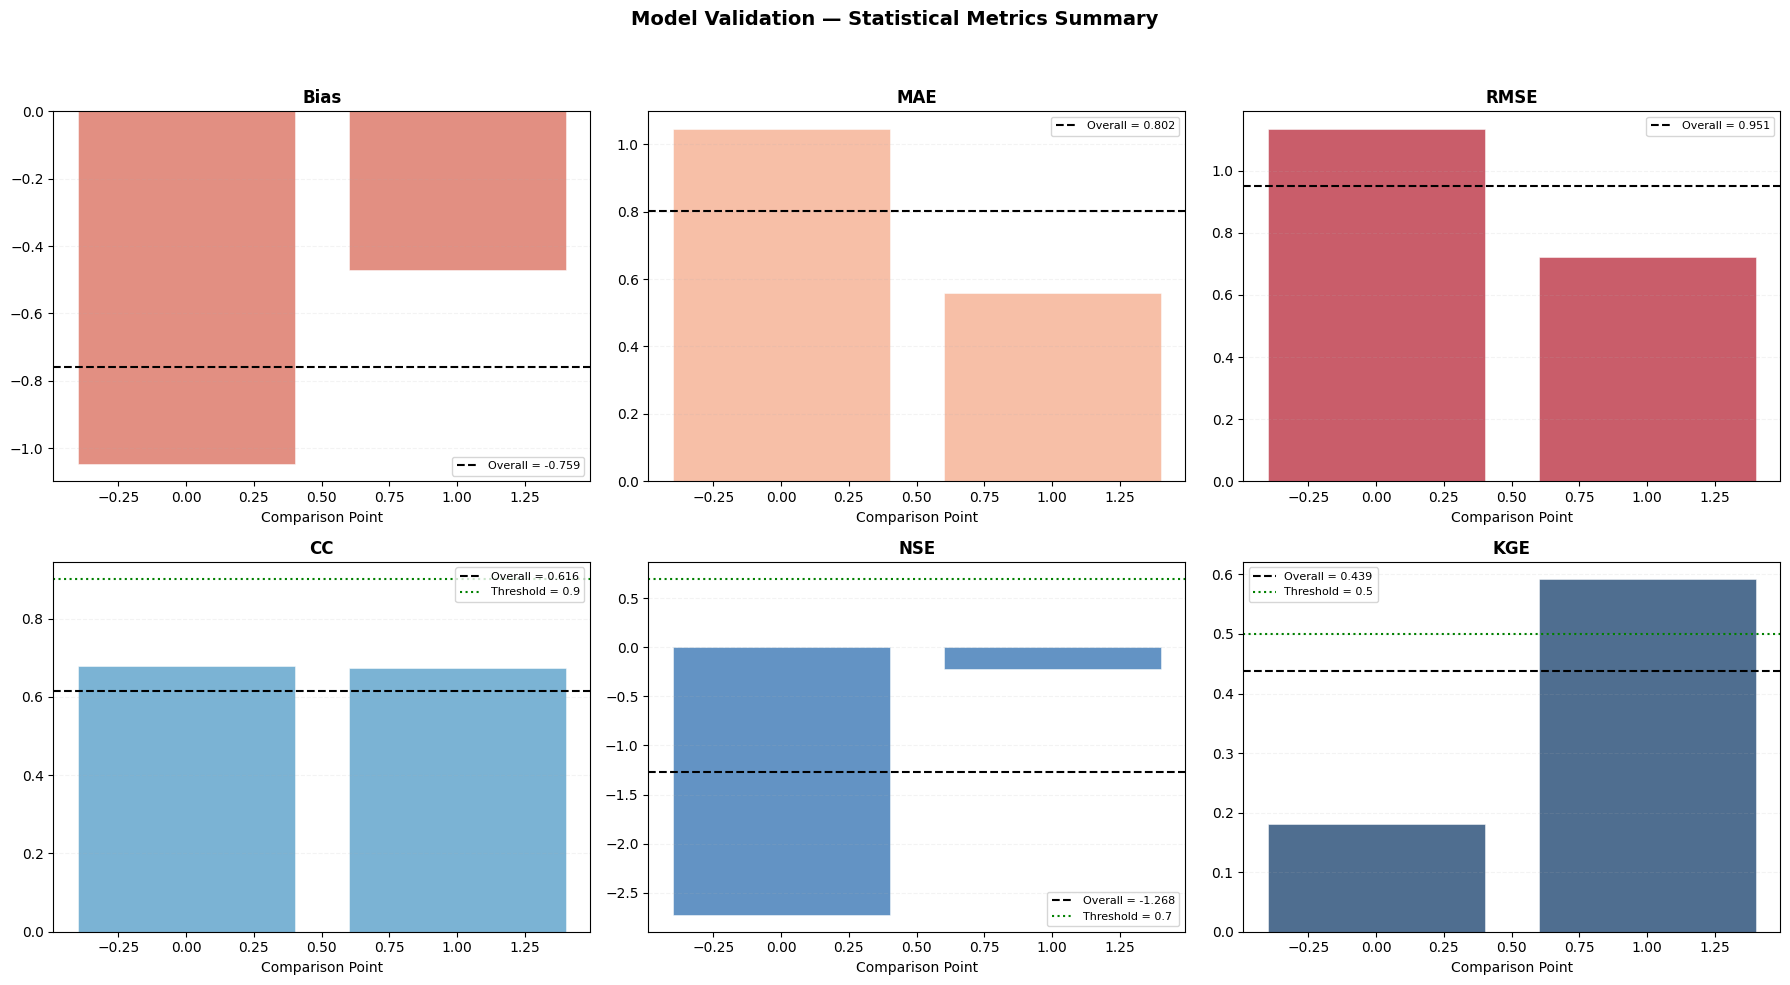

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Validation \u2014 Statistical Metrics Summary',
             fontsize=14, fontweight='bold')

metric_names = ['Bias', 'MAE', 'RMSE', 'CC', 'NSE', 'KGE']
bar_colors = ['#d6604d', '#f4a582', '#b2182b', '#4393c3', '#2166ac', '#053061']
thresholds = {'CC': 0.90, 'NSE': 0.70, 'KGE': 0.50}

for ax, mname, color in zip(axes.flat, metric_names, bar_colors):
    per_point = [validation_metrics(m['sim'], m['obs'])[mname]
                 for m in matched]

    ax.bar(range(len(per_point)), per_point,
           color=color, alpha=0.7, edgecolor='white', lw=0.5)

    ax.axhline(overall_metrics[mname], color='k', ls='--', lw=1.5,
               label=f'Overall = {overall_metrics[mname]:.3f}')

    if mname in thresholds:
        ax.axhline(thresholds[mname], color='green', ls=':', lw=1.5,
                   label=f'Threshold = {thresholds[mname]}')

    ax.set_title(mname, fontsize=12, fontweight='bold')
    ax.set_xlabel('Comparison Point')
    ax.legend(fontsize=8, loc='best')
    ax.grid(True, alpha=0.15, ls='--', axis='y')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Summary

This notebook demonstrated a complete model calibration and validation workflow for the SWAN wave model:

| Phase | Component | Purpose |
|-------|-----------|--------|
| **Calibration** | Parameter sweep framework | Systematically vary $C_{ds}$, $C_f$, $\gamma$ to minimise error |
| **Calibration** | Results ranking table | Identify optimal parameter set by KGE |
| **Validation** | Time series comparison | Visual check of peak timing and magnitude |
| **Validation** | Scatter plot | Overall bias and spread assessment |
| **Validation** | Taylor diagram | Simultaneous view of CC, std ratio, and RMSD |
| **Validation** | Metrics summary | Quantitative per-point and overall performance |

### Key Functions Used

- `swan_runner.read_table()` — parses SWAN TABLE text output
- `validation_metrics()` — computes Bias, MAE, RMSE, CC, NSE, KGE
- `match_era5_swan()` — spatially matches ERA5 grid points to SWAN output sites

### Interpretation Guide

- **CC > 0.90** indicates the model captures the timing of wave events well
- **Bias close to 0** means no systematic over- or under-prediction
- **KGE > 0.50** is generally considered acceptable for wave models
- **Taylor diagram points near the reference** represent near-perfect model skill

### References

- Taylor, K.E. (2001). Summarizing multiple aspects of model performance in a single diagram. *J. Geophys. Res.*, 106(D7), 7183–7192.
- Gupta, H.V., et al. (2009). Decomposition of the mean squared error and NSE performance criteria. *J. Hydrology*, 377(1-2), 80–91.